*Project*: AquaStock Intelligence

Smart Inventory & Demand Prediction for Aquatic E-Commerce

*Data used*: the monthly ML table (12,960 rows; 144 product lines × 5 cities × 18 months, Oct 2024 – Mar 2026) and a 10,000-row cleaned transaction sample.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", font_scale=0.75)
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams.update({
    "font.size": 8,
    "axes.titlesize": 10,
    "axes.labelsize": 8,
    "xtick.labelsize": 7,
    "ytick.labelsize": 7,
    "legend.fontsize": 7,
    "legend.title_fontsize": 8,
})

ml = pd.read_csv("../data/aquatic_demand_ml_dataset.csv", parse_dates=["month_start"])
tx = pd.read_csv("../data/aquatic_transactions_clean_10k.csv", parse_dates=["purchase_date"])

print("ML table  :", ml.shape)
print("Transactions:", tx.shape)

ML table  : (12960, 52)
Transactions: (10000, 42)


Step 1: Understand the data

What was done: loaded both files, checked shapes, data types, missing values and date range.

Conclusion: the data is clean (0 missing values) and ready for analysis. The target demand means the number of transactions per product line, per city, per month.

In [ ]:
ml.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12960 entries, 0 to 12959
Data columns (total 52 columns):
 #   Column                  Non-Null Count  Dtype         
---  ------                  --------------  -----         
 0   month_start             12960 non-null  datetime64[ns]
 1   category                12960 non-null  object        
 2   subcategory             12960 non-null  object        
 3   brand                   12960 non-null  object        
 4   product_line            12960 non-null  object        
 5   product_line_id         12960 non-null  int64         
 6   location                12960 non-null  object        
 7   split                   12960 non-null  object        
 8   demand                  12960 non-null  int64         
 9   year                    12960 non-null  int64         
 10  month_num               12960 non-null  int64         
 11  quarter                 12960 non-null  int64         
 12  days_in_month           12960 non-null  int64 

In [ ]:
print("Missing values (ML table):", ml.isnull().sum().sum())
print("Missing values (Transactions):", tx.isnull().sum().sum())
print("Date range:", ml["month_start"].min().date(), "to", ml["month_start"].max().date())
print("Product lines:", ml["product_line"].nunique(), "| Cities:", ml["location"].nunique())
ml[["demand", "avg_price", "avg_discount", "avg_stock", "return_rate"]].describe().round(2)

Missing values (ML table): 0
Missing values (Transactions): 0
Date range: 2024-10-01 to 2026-03-01
Product lines: 144 | Cities: 5


,demand,avg_price,avg_discount,avg_stock,return_rate
count,12960.00,12960.00,12960.00,12960.00,12960.00
mean,51.00,15197.31,28.33,249.78,0.12
std,20.47,16104.29,5.93,21.47,0.05
min,16.00,1975.48,15.75,150.26,0.00
25%,38.00,2799.25,24.56,235.74,0.08
50%,45.00,8024.48,27.17,249.62,0.11
75%,54.00,17149.19,29.46,263.71,0.15
max,131.00,55017.20,48.53,340.04,0.35


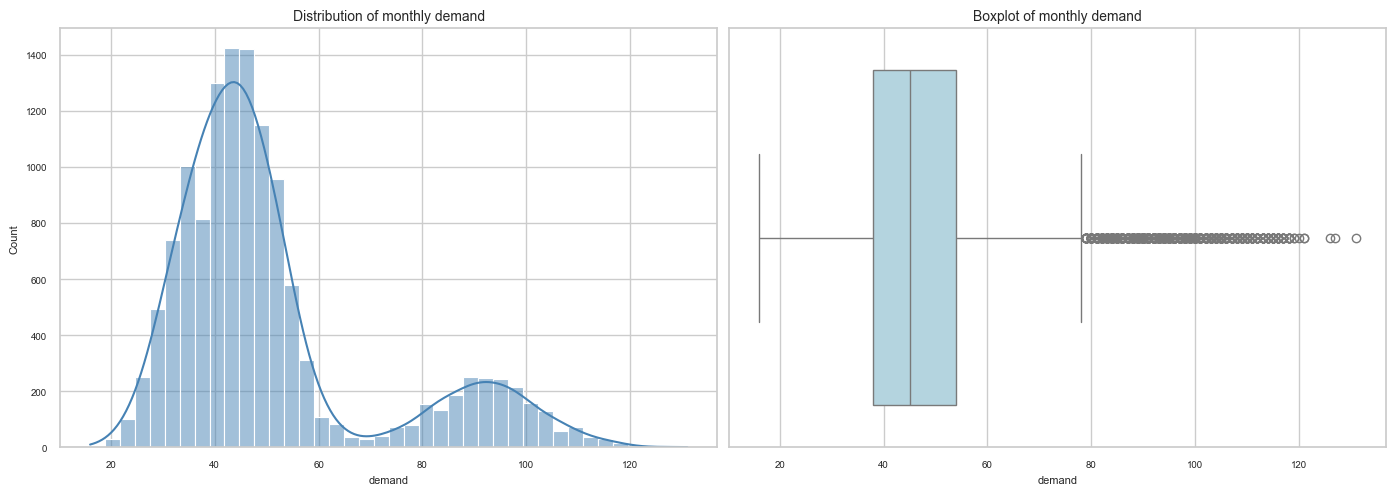

Mean: 51.0 | Median: 45.0 | Max: 131


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(ml["demand"], bins=40, kde=True, ax=axes[0], color="steelblue")
axes[0].set_title("Distribution of monthly demand")
sns.boxplot(x=ml["demand"], ax=axes[1], color="lightblue")
axes[1].set_title("Boxplot of monthly demand")
plt.tight_layout()
plt.show()

print("Mean:", ml["demand"].mean().round(1), "| Median:", ml["demand"].median(), "| Max:", ml["demand"].max())

Step 2: Distribution of the target (demand)

What was done: histogram, KDE and boxplot of monthly demand.

Conclusion:

Average demand is 51, median 45, and most values lie between 38 and 54.
The maximum is 131, so the distribution is slightly right-skewed, with a few high-demand product lines.

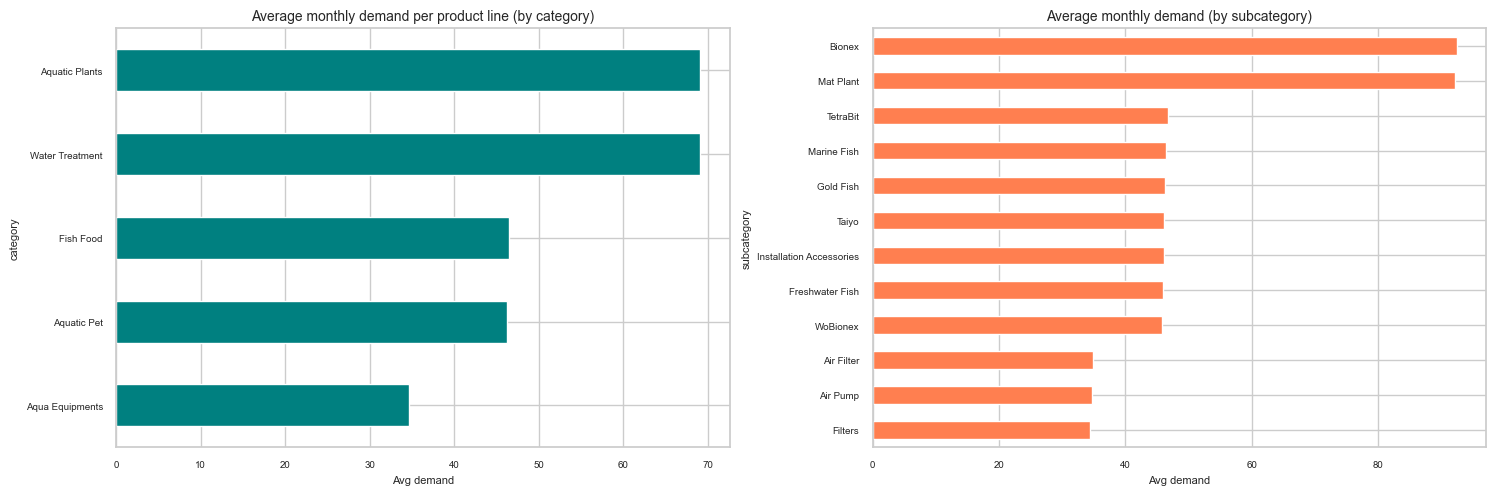

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

cat = ml.groupby("category")["demand"].mean().sort_values()
cat.plot(kind="barh", ax=axes[0], color="teal")
axes[0].set_title("Average monthly demand per product line (by category)")
axes[0].set_xlabel("Avg demand")

sub = ml.groupby("subcategory")["demand"].mean().sort_values()
sub.plot(kind="barh", ax=axes[1], color="coral")
axes[1].set_title("Average monthly demand (by subcategory)")
axes[1].set_xlabel("Avg demand")

plt.tight_layout()
plt.show()

Step 3: Demand by category and subcategory

What was done: bar charts of average demand per product line.

Conclusion:

Highest: Aquatic Plants and Water Treatment (about 69 each).
Lowest: Aqua Equipments (about 35).
The gap is by design of the product mix: Aqua Equipments has 36 product lines versus 24 for the top two, so this is a per-line comparison, not total demand.
The same split gives the slow-moving candidates later: Filters, Air Pump and Air Filter.

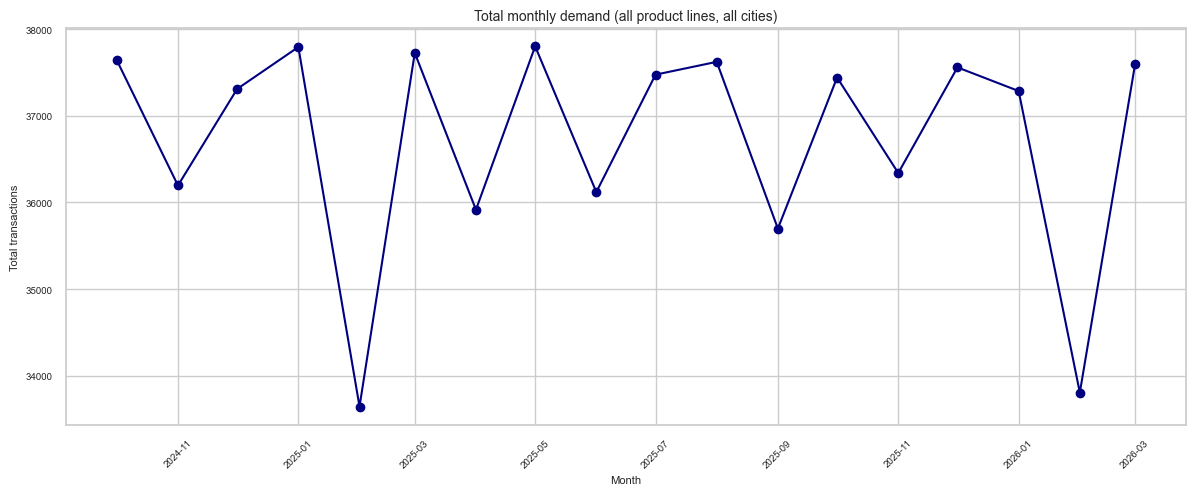

In [ ]:
monthly_total = ml.groupby("month_start")["demand"].sum()

plt.figure(figsize=(12, 5))
plt.plot(monthly_total.index, monthly_total.values, marker="o", color="navy")
plt.title("Total monthly demand (all product lines, all cities)")
plt.xlabel("Month"); plt.ylabel("Total transactions")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

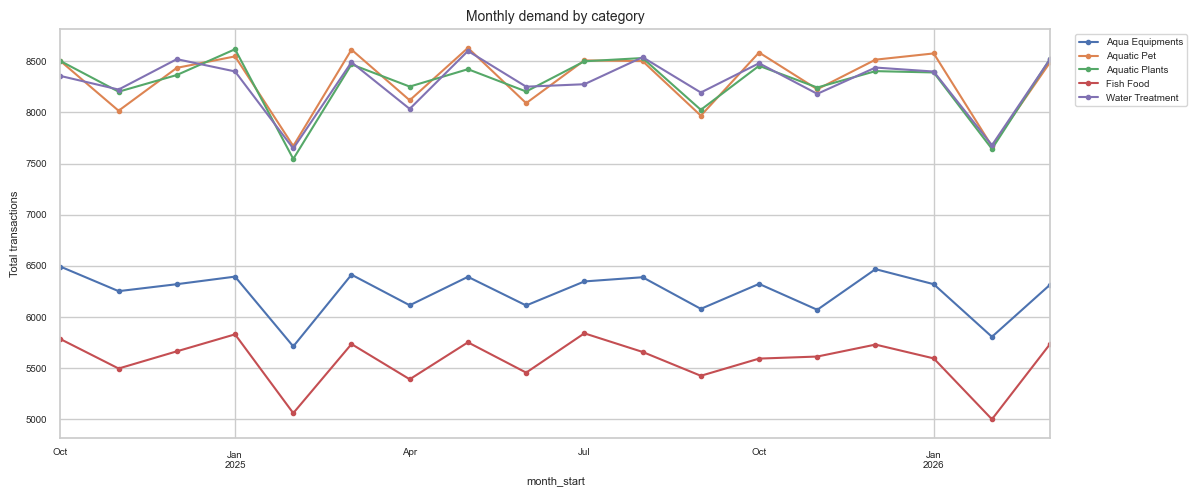

In [ ]:
by_cat = ml.groupby(["month_start", "category"])["demand"].sum().unstack()
by_cat.plot(figsize=(12, 5), marker=".")
plt.title("Monthly demand by category")
plt.ylabel("Total transactions")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

Step 4: Time trend

What was done: line charts of total monthly demand, overall and by category.

Conclusion: there is no upward or downward trend and no seasonal pattern. Total demand stays between about 33.6k and 37.8k per month. The only dips are in February.

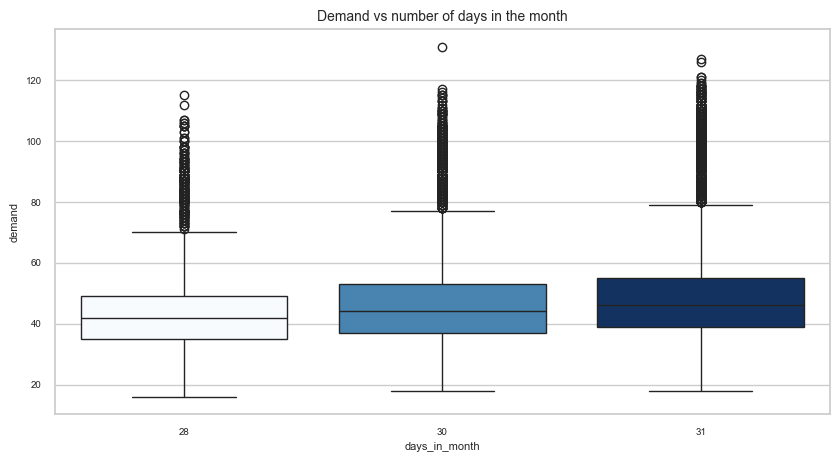

days_in_month
28    46.8
30    50.1
31    52.2
Name: demand, dtype: float64


In [ ]:
sns.boxplot(x="days_in_month", y="demand", hue="days_in_month", data=ml, palette="Blues", legend=False)
plt.title("Demand vs number of days in the month")
plt.show()

print(ml.groupby("days_in_month")["demand"].mean().round(1))

Step 5: Effect of days in the month

What was done: boxplot and averages of demand by days_in_month.

Conclusion: more days means more demand: about 47 (28 days), 50 (30 days), 52 (31 days). The February dip is a day-count effect, not a drop in customer interest, so days_in_month is an important model feature.

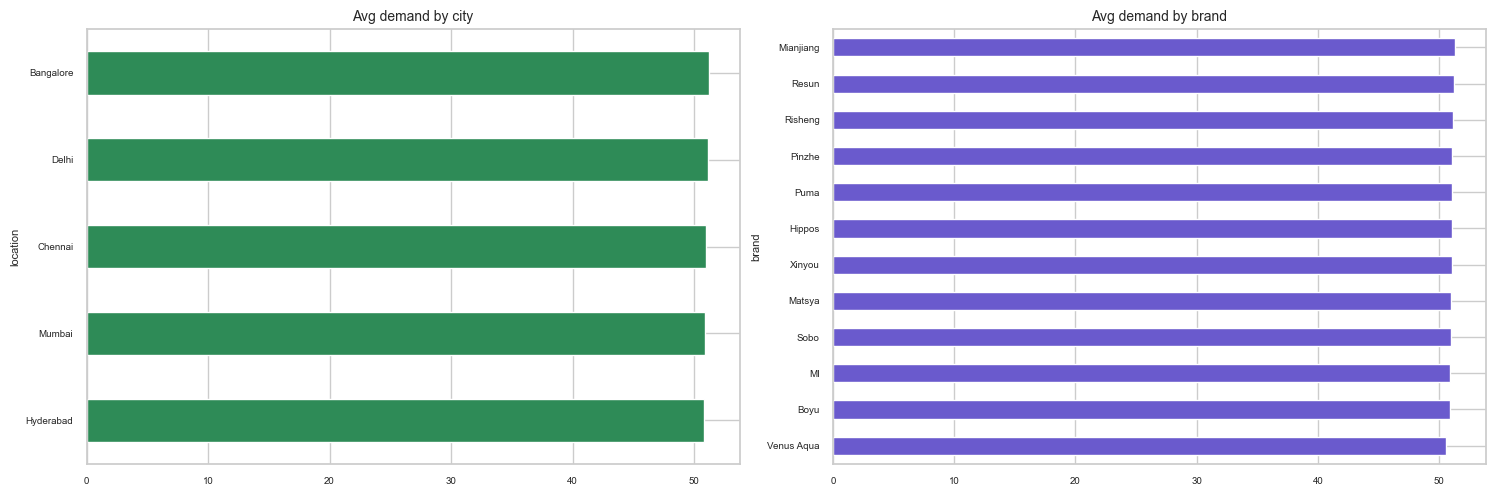

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

ml.groupby("location")["demand"].mean().sort_values().plot(kind="barh", ax=axes[0], color="seagreen")
axes[0].set_title("Avg demand by city")

ml.groupby("brand")["demand"].mean().sort_values().plot(kind="barh", ax=axes[1], color="slateblue")
axes[1].set_title("Avg demand by brand")

plt.tight_layout()
plt.show()

Step 6: City and brand comparison

What was done: bar charts of average demand by city and by brand.

Conclusion: cities (50.9 to 51.2) and brands (50.5 to 51.3) are almost identical, so neither is a strong predictor on its own.

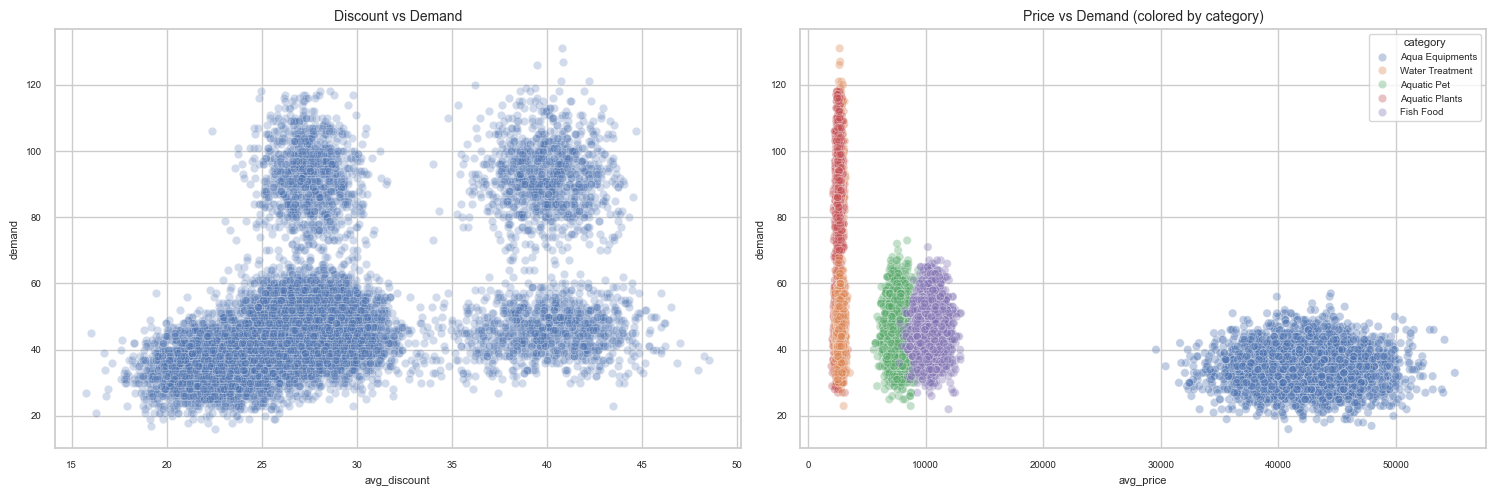

Correlation discount-demand: 0.473
Correlation price-demand   : -0.529


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.scatterplot(data=ml, x="avg_discount", y="demand", alpha=0.25, ax=axes[0])
axes[0].set_title("Discount vs Demand")

sns.scatterplot(data=ml, x="avg_price", y="demand", hue="category", alpha=0.35, ax=axes[1])
axes[1].set_title("Price vs Demand (colored by category)")

plt.tight_layout()
plt.show()

print("Correlation discount-demand:", ml["avg_discount"].corr(ml["demand"]).round(3))
print("Correlation price-demand   :", ml["avg_price"].corr(ml["demand"]).round(3))

In [ ]:
within = ml.groupby("category").apply(
    lambda g: pd.Series({
        "corr_discount_demand": g["avg_discount"].corr(g["demand"]),
        "corr_price_demand": g["avg_price"].corr(g["demand"]),
    }), include_groups=False
).round(3)
within

,corr_discount_demand,corr_price_demand
category,,
Aqua Equipments,-0.010,0.009
Aquatic Pet,0.006,-0.013
Aquatic Plants,-0.031,0.005
Fish Food,-0.039,-0.002
Water Treatment,-0.026,-0.022


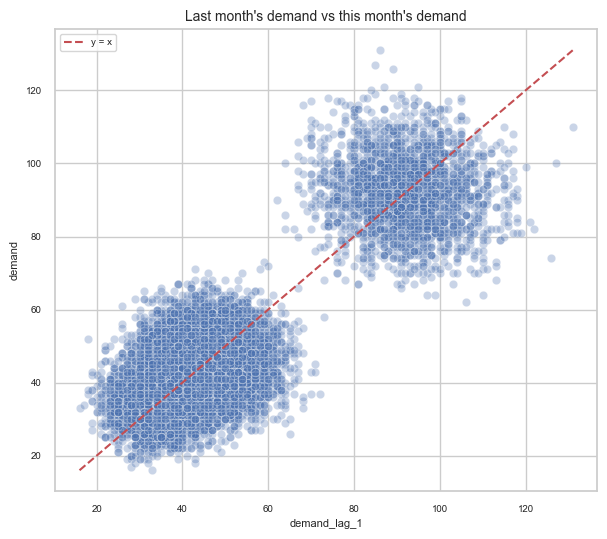

Correlation lag_1 vs demand        : 0.862
Correlation roll_mean_3 vs demand  : 0.908


In [ ]:
plt.figure(figsize=(7, 6))
sns.scatterplot(data=ml, x="demand_lag_1", y="demand", alpha=0.3)
plt.plot([ml.demand.min(), ml.demand.max()], [ml.demand.min(), ml.demand.max()], "r--", label="y = x")
plt.title("Last month's demand vs this month's demand")
plt.legend()
plt.show()

print("Correlation lag_1 vs demand        :", ml["demand_lag_1"].corr(ml["demand"]).round(3))
print("Correlation roll_mean_3 vs demand  :", ml["demand_roll_mean_3"].corr(ml["demand"]).round(3))

Step 8: Last month’s demand vs this month’s

What was done: scatter plot and correlations of lag features.

Conclusion: demand_lag_1 correlates 0.86 with demand and demand_roll_mean_3 correlates 0.91. Past demand is the strongest predictor, so lag and rolling features are worth using.

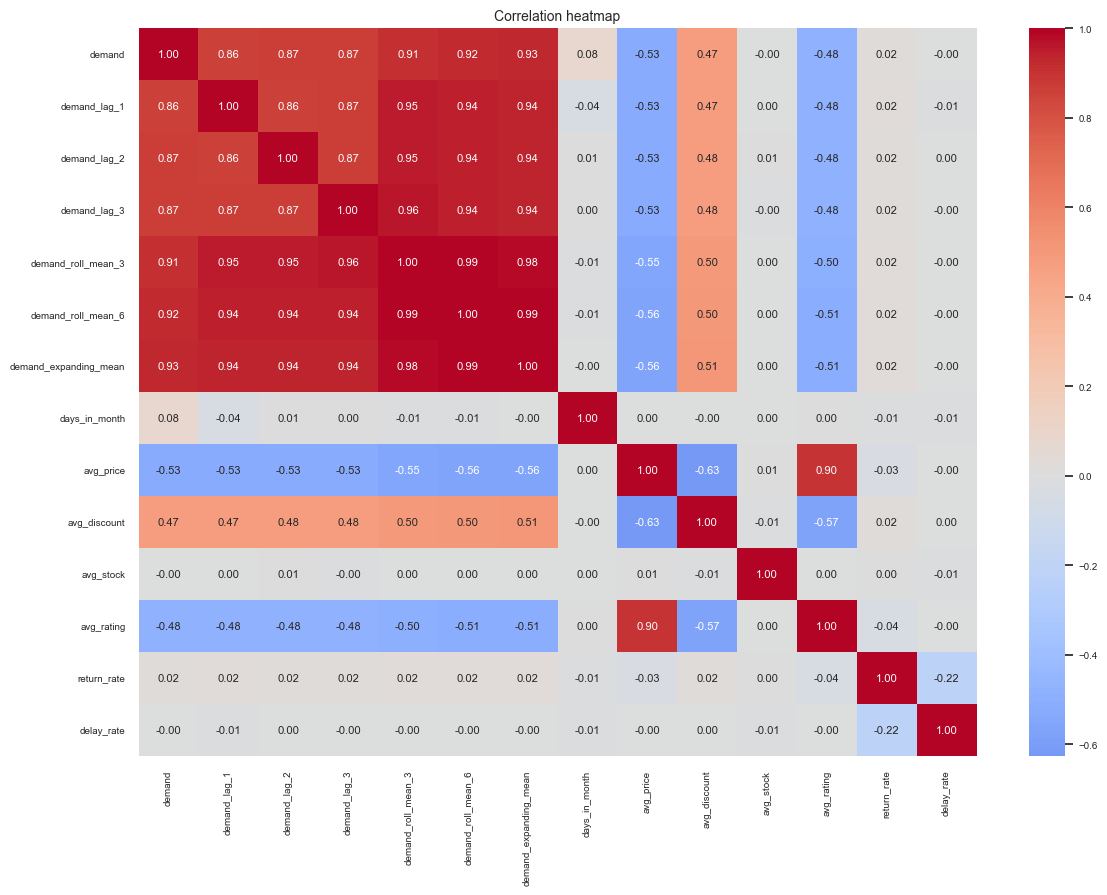

In [ ]:
cols = ["demand", "demand_lag_1", "demand_lag_2", "demand_lag_3", "demand_roll_mean_3",
        "demand_roll_mean_6", "demand_expanding_mean", "days_in_month",
        "avg_price", "avg_discount", "avg_stock", "avg_rating", "return_rate", "delay_rate"]

plt.figure(figsize=(12, 9))
sns.heatmap(ml[cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation heatmap")
plt.tight_layout()
plt.show()

Step 9: Correlation heatmap

What was done: heatmap of 14 numeric columns.

Conclusion: demand history features (lags, rolling and expanding means) are the most strongly related to demand. Price, discount, stock, rating, return rate and delay rate show weak links.

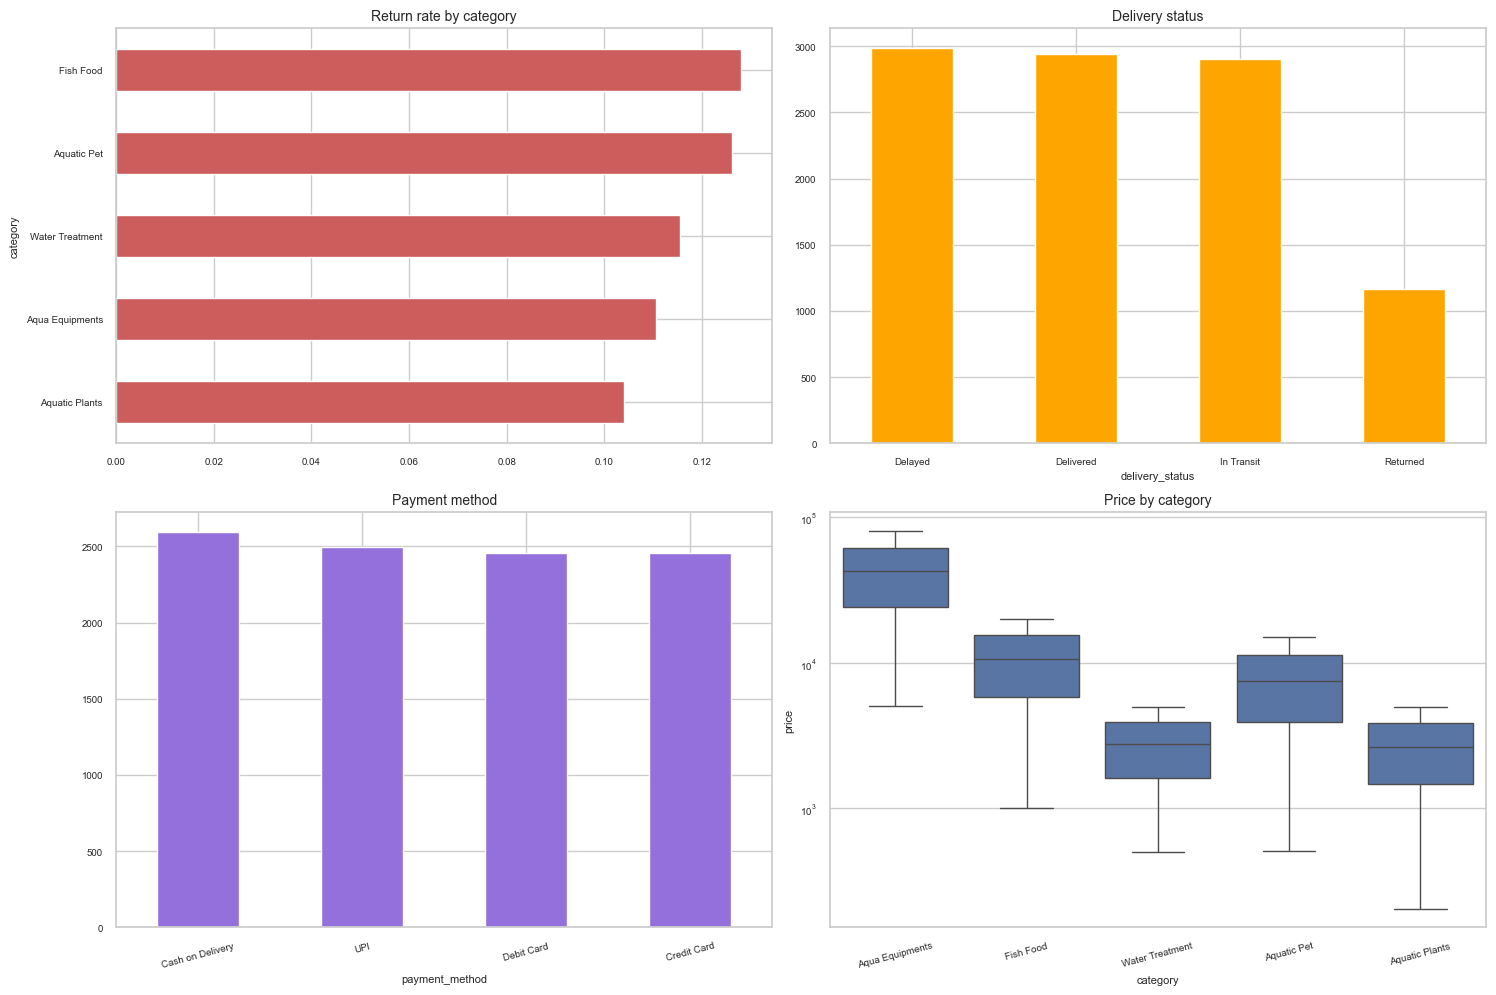

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

tx.groupby("category")["is_returned"].mean().sort_values().plot(kind="barh", ax=axes[0, 0], color="indianred")
axes[0, 0].set_title("Return rate by category")

tx["delivery_status"].value_counts().plot(kind="bar", ax=axes[0, 1], color="orange")
axes[0, 1].set_title("Delivery status")
axes[0, 1].tick_params(axis="x", rotation=0)

tx["payment_method"].value_counts().plot(kind="bar", ax=axes[1, 0], color="mediumpurple")
axes[1, 0].set_title("Payment method")
axes[1, 0].tick_params(axis="x", rotation=15)

sns.boxplot(data=tx, x="category", y="price", ax=axes[1, 1])
axes[1, 1].set_title("Price by category")
axes[1, 1].set_yscale("log")
axes[1, 1].tick_params(axis="x", rotation=15)

plt.tight_layout()
plt.show()

In [ ]:
print("Overall return rate :", (tx["is_returned"].mean() * 100).round(1), "%")
print("Delayed deliveries  :", (tx["is_delayed"].mean() * 100).round(1), "%")
print("Repeat customers    :", (tx["is_repeat_customer"].mean() * 100).round(1), "%")
print("Avg discount        :", tx["discount"].mean().round(1), "%")
print()
print(tx.groupby("category")[["price", "discount", "rating"]].mean().round(2))

Overall return rate : 11.6 %
Delayed deliveries  : 29.9 %
Repeat customers    : 62.9 %
Avg discount        : 29.1 %

                    price  discount  rating
category                                   
Aqua Equipments  42809.90     22.27    4.22
Aquatic Pet       7525.95     27.19    3.87
Aquatic Plants    2644.45     27.03    3.82
Fish Food        10598.15     27.64    3.94
Water Treatment   2766.51     39.29    3.82


Step 10: Business insights (10k transactions)

What was done: charts of returns, delivery status, payment method and price by category.

Conclusion:

Metric	Value
Overall return rate	11.6% (10.4% to 12.8% across categories)
Delayed deliveries	29.9%
Repeat customers	62.9%
Average discount	29.1%
Payment split	roughly equal (COD 25.9%, UPI 25.0%, debit 24.6%, credit 24.5%)

Prices are strongly category-bound (Aquatic Plants ~₹200 to ₹5,000 versus Aqua Equipments ~₹5,000 to ₹80,000), which is why price must be compared within a category.

Our Findings in Simple Words

1. How much do products sell in a month?

On average, a product line gets about 51 orders in a month. Most of the time it is somewhere between 38 and 54 orders. A few product lines sell much more, with the highest reaching 131.

2. Which products sell the most and the least?

Aquatic Plants and Water Treatment sell the most (about 69 orders per product line). Aqua Equipments sell the least (about 35). Equipment is expensive, so fewer people buy it.

3. Is business growing or falling?

Neither. Sales stay almost the same from month to month, at about 34,000 to 38,000 orders in total. They do not go steadily up or down.

4. Why is February lower?

February has only 28 days, so it has fewer days to sell. Customers did not lose interest. A 28-day month gets about 47 orders per product line, a 30-day month about 50, and a 31-day month about 52.

5. Do discounts bring more customers?

It looks like they do when you mix all products together, but that is a trick. Discounts and sales are not truly linked. If you compare products of the same type, the link almost disappears. The mix-up happens because different product types have different prices, discounts and sales to begin with.

6. Does last month’s sales help predict this month’s?

Yes, very much. Last month’s sales match this month’s closely (0.86 on a scale where 1 is a perfect match), and the average of the last three months matches even better (0.91). So the model should use past sales to predict future sales.



The big picture in 4 lines

Sales are steady, so the future will probably look like the past.

Past sales and the number of days in the month are the best clues for prediction.

City, brand, price and discount are weak clues.

Do not say “discounts increase sales”. The data does not show that.